# 01. What is in the 13F data?

First look at the downloaded data, before making any graph choices.

Each quarter, large US institutional managers file a Form 13F listing their holdings. One row means: *this manager held this security at the end of this quarter.* That row is a future **manager-stock edge** in our bipartite graph.

Run `src/s01_download_13f.py` first. Charts are saved to `figures/`.

In [1]:
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from config import INTERIM, MAIN_QUARTER, QUARTERS, RAW, RESULTS

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
BLUE, MUTED, GRID, INK, SOFT = "#2a78d6", "#b9b7ae", "#e6e5df", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": MUTED, "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.titleweight": "bold", "text.color": INK, "axes.labelcolor": SOFT,
    "xtick.color": SOFT, "ytick.color": SOFT, "xtick.bottom": False, "ytick.left": False,
})
pd.set_option("display.max_colwidth", 42)

## One filing, as an example
The largest positions of one well-known manager. `VALUE` is in dollars; `CUSIP` identifies the security.

In [2]:
h = pd.read_parquet(INTERIM / f"holdings_{MAIN_QUARTER}.parquet")
managers = pd.read_parquet(INTERIM / f"managers_{MAIN_QUARTER}.parquet")
example = managers[managers["FILINGMANAGER_NAME"].str.upper().str.contains("BERKSHIRE HATHAWAY INC")].iloc[0]
rows = h[h["CIK"] == example["CIK"]].sort_values("VALUE", ascending=False)
print(example["FILINGMANAGER_NAME"], "|", len(rows), "rows, total value $%.0fbn" % (rows["VALUE"].sum() / 1e9))
rows[["NAMEOFISSUER", "TITLEOFCLASS", "CUSIP", "VALUE", "SHARES"]].head(6)

Berkshire Hathaway Inc | 89 rows, total value $299bn


,NAMEOFISSUER,TITLEOFCLASS,CUSIP,VALUE,SHARES
186424,AMERICAN EXPRESS CO,COM,025816109,5.041990e+10,149061045
186422,ALPHABET INC,CAP STK CL A,02079K305,2.352369e+10,65824467
186435,APPLE INC,COM,037833100,2.334117e+10,80664820
186459,COCA COLA CO,COM,191216100,2.297688e+10,282722729
186432,APPLE INC,COM,037833100,1.780808e+10,61542988
186443,BANK OF AMER CORP,COM,060505104,1.759591e+10,308808515


## 1. Size over time
Are the nine quarters comparable, or does something jump?

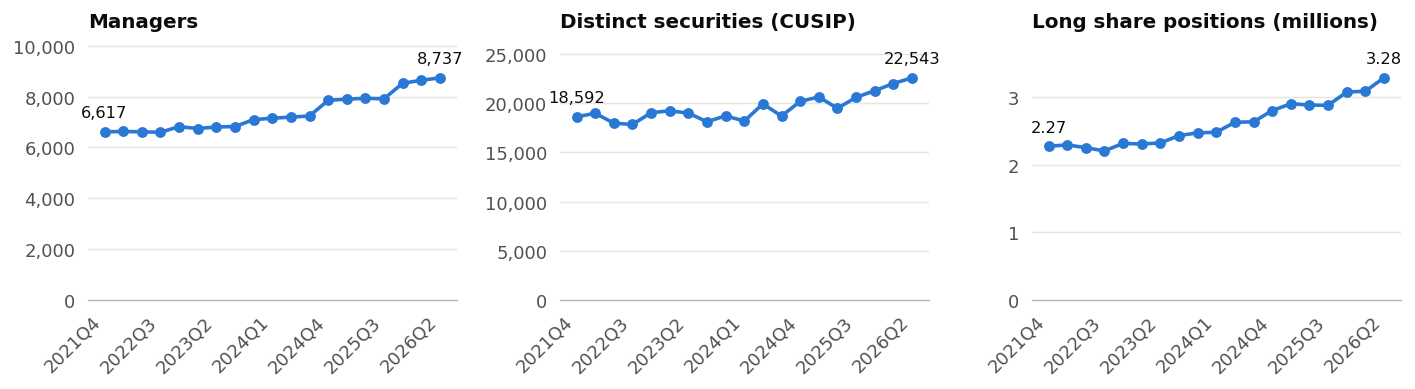

Growth from the first to the last quarter: {'managers': 0.32, 'cusips': 0.213, 'rows_long_shares': 0.445}
Manager change per quarter: {'2022Q1': 12, '2022Q2': -13, '2022Q3': -18, '2022Q4': 220, '2023Q1': -72, '2023Q2': 60, '2023Q3': 18, '2023Q4': 272, '2024Q1': 53, '2024Q2': 47, '2024Q3': 42, '2024Q4': 615, '2025Q1': 47, '2025Q2': 33, '2025Q3': -18, '2025Q4': 610, '2026Q1': 117, '2026Q2': 95}


In [3]:
log = pd.read_csv(RESULTS / "quarter_log.csv", index_col=0)
assert list(log.index) == list(QUARTERS)
panels = [("managers", "Managers"), ("cusips", "Distinct securities (CUSIP)"), ("rows_long_shares", "Long share positions (millions)")]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.1))
for ax, (col, title) in zip(axes, panels):
    y = log[col] / (1e6 if col == "rows_long_shares" else 1)
    ax.plot(log.index, y, color=BLUE, lw=2, marker="o", ms=5)
    ax.set_ylim(0, y.max() * 1.18)
    ax.set_title(title)
    ticks = list(range(0, len(log), 3))
    ax.set_xticks(ticks)
    ax.set_xticklabels([log.index[i] for i in ticks], rotation=45, ha="right")
    fmt = "{:.2f}" if col == "rows_long_shares" else "{:,.0f}"
    for i in (0, len(y) - 1):
        ax.annotate(fmt.format(y.iloc[i]), (i, y.iloc[i]), xytext=(0, 8), textcoords="offset points", ha="center", color=INK, fontsize=9)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 10 else f"{v:g}"))
fig.tight_layout()
fig.savefig(FIGURES / "eda_size_over_time.png")
plt.show()
growth = log[["managers", "cusips", "rows_long_shares"]].iloc[-1] / log[["managers", "cusips", "rows_long_shares"]].iloc[0] - 1
print("Growth from the first to the last quarter:", growth.round(3).to_dict())
print("Manager change per quarter:", log["managers"].diff().dropna().astype(int).to_dict())

## 2. What do the filters remove?
Starting from every row in the latest release. We want a snapshot of **long stock positions at one date**, so we drop other report periods, amendments, options and bonds.

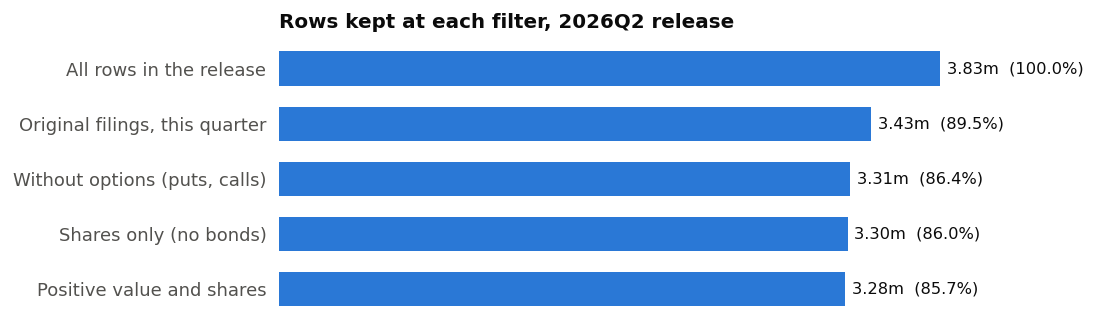

Submission types in the release: {'13F-HR': 9501, '13F-NT': 1946, '13F-HR/A': 399, '13F-NT/A': 6}
Filings from other report periods: 912
Option rows in the filing set: 119663  value $6.92tn


,rows,value_tn,rows_pct,value_pct
All rows in the release,3830274,83.98,100.0,100.0
"Original filings, this quarter",3429763,79.72,89.5,94.9
"Without options (puts, calls)",3310100,72.80,86.4,86.7
Shares only (no bonds),3295587,72.60,86.0,86.4
Positive value and shares,3281353,72.60,85.7,86.4


In [4]:
period, release = QUARTERS[MAIN_QUARTER]
with zipfile.ZipFile(RAW / "13f" / f"{release}_form13f.zip") as z:
    member = {n.rsplit("/", 1)[-1]: n for n in z.namelist()}
    with z.open(member["SUBMISSION.tsv"]) as fh:
        sub = pd.read_csv(fh, sep="\t", dtype=str)
    with z.open(member["INFOTABLE.tsv"]) as fh:
        raw = pd.read_csv(fh, sep="\t", dtype=str, usecols=["ACCESSION_NUMBER", "VALUE", "SSHPRNAMT", "SSHPRNAMTTYPE", "PUTCALL"])
raw["VALUE"] = pd.to_numeric(raw["VALUE"], errors="coerce")
raw["SHARES"] = pd.to_numeric(raw["SSHPRNAMT"], errors="coerce")
keep = sub[(sub["PERIODOFREPORT"] == period) & (sub["SUBMISSIONTYPE"] == "13F-HR")]
keep = keep.sort_values("ACCESSION_NUMBER").drop_duplicates("CIK", keep="last")
a = raw
b = a[a["ACCESSION_NUMBER"].isin(keep["ACCESSION_NUMBER"])]
c = b[b["PUTCALL"].isna()]
d = c[c["SSHPRNAMTTYPE"] == "SH"]
e = d[(d["VALUE"] > 0) & (d["SHARES"] > 0)]
stages = [("All rows in the release", a), ("Original filings, this quarter", b), ("Without options (puts, calls)", c),
          ("Shares only (no bonds)", d), ("Positive value and shares", e)]
funnel = pd.DataFrame({"rows": [len(x) for _, x in stages], "value_tn": [x["VALUE"].sum() / 1e12 for _, x in stages]},
                      index=[n for n, _ in stages])
funnel["rows_pct"] = (funnel["rows"] / len(a) * 100).round(1)
funnel["value_pct"] = (funnel["value_tn"] / funnel["value_tn"].iloc[0] * 100).round(1)
assert len(e) >= log.loc[MAIN_QUARTER, "rows_long_shares"]  # step 1 also drops malformed CUSIPs

fig, ax = plt.subplots(figsize=(8, 2.8))
labels = funnel.index[::-1]
ax.barh(labels, funnel["rows"][::-1] / 1e6, color=BLUE, height=0.62)
for i, name in enumerate(labels):
    ax.text(funnel.loc[name, "rows"] / 1e6 + 0.04, i, f"{funnel.loc[name, 'rows'] / 1e6:.2f}m  ({funnel.loc[name, 'rows_pct']:.1f}%)", va="center", fontsize=9)
ax.set_xlim(0, funnel["rows"].max() / 1e6 * 1.22)
ax.grid(False)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title(f"Rows kept at each filter, {MAIN_QUARTER} release")
fig.savefig(FIGURES / "eda_filter_funnel.png")
plt.show()
print("Submission types in the release:", sub["SUBMISSIONTYPE"].value_counts().to_dict())
print("Filings from other report periods:", int((sub["PERIODOFREPORT"] != period).sum()))
print("Option rows in the filing set:", len(b) - len(c), " value $%.2ftn" % ((b["VALUE"].sum() - c["VALUE"].sum()) / 1e12))
funnel.round(2)

## 3. How big are portfolios?
This matters most for the model. In the projection, a manager holding *n* stocks creates about n²/2 stock pairs. So managers holding thousands of stocks dominate the graph, while telling us little about which stocks belong together.

The log scale is needed because portfolio sizes span several orders of magnitude.

Managers whose reported value is flagged unreliable (their holdings still count, their money does not): 188 of 8737


Positions per manager: {'count': 8737.0, 'mean': 228.0, 'std': 485.0, 'min': 1.0, '10%': 11.0, '25%': 32.0, '50%': 80.0, '75%': 184.0, '90%': 516.0, '99%': 2779.0, 'max': 6060.0}


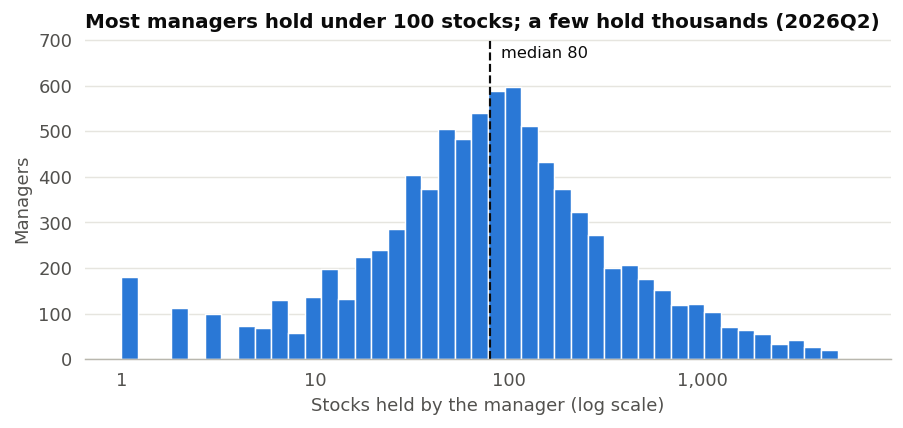

In [5]:
h["ISSUER"] = h["CUSIP"].str[:6]
flagged = ~h.drop_duplicates("CIK").set_index("CIK")["VALUE_RELIABLE"]
print(f"Managers whose reported value is flagged unreliable (their holdings still count, their money does not): {int(flagged.sum())} of {len(flagged)}")
pos = h.assign(VALUE=h["VALUE"].where(h["VALUE_RELIABLE"], 0)).groupby(["CIK", "ISSUER"], as_index=False)["VALUE"].sum()
size = pos.groupby("CIK").size()
print("Positions per manager:", size.describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(0).to_dict())

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.logspace(0, np.log10(size.max()), 45)
ax.hist(size, bins=bins, color=BLUE, edgecolor="white", linewidth=0.8)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Stocks held by the manager (log scale)")
ax.set_ylabel("Managers")
ax.axvline(size.median(), color=INK, lw=1.2, ls="--")
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
ax.annotate(f"median {size.median():.0f}", (size.median(), ax.get_ylim()[1] * .94), xytext=(6, 0), textcoords="offset points", fontsize=9)
ax.set_title(f"Most managers hold under 100 stocks; a few hold thousands ({MAIN_QUARTER})")
fig.savefig(FIGURES / "eda_portfolio_sizes.png")
plt.show()

### Who would the provisional 10-200 filter keep?
The filter counts positions **inside the universe of the 1,000 largest issuers**. This notebook uses a simple stand-in for the real universe: the top 1,000 issuers by value, funds included (the sector mapping came later, see notebook 02). Managers flagged as unreliable on value show 0 money here, for example JPMorgan in this quarter.

Each band is shown three ways, because share of managers and share of money can tell very different stories.

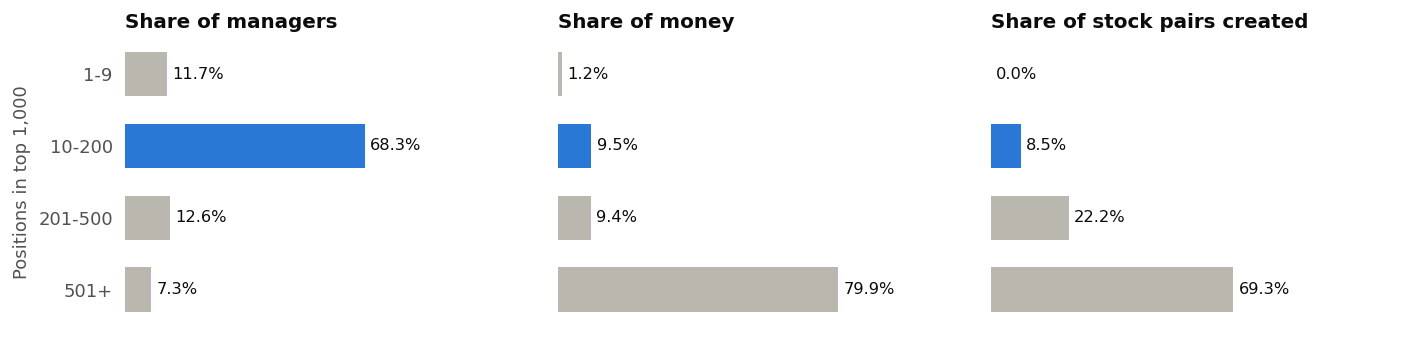

,managers,positions,stock_pairs,value
1-9,11.7,0.3,0.0,1.2
10-200,68.3,34.4,8.5,9.5
201-500,12.6,27.6,22.2,9.4
501+,7.3,37.7,69.3,79.9


,positions_in_top1000,FILINGMANAGER_NAME,value_bn
CIK,,,
0000019617,999,JPMORGAN CHASE & CO,0.0
0000853758,999,MERCER GLOBAL ADVISORS INC /ADV,78.0
0000895421,999,MORGAN STANLEY,1762.0
0001000275,999,ROYAL BANK OF CANADA,567.0
0001610520,999,UBS Group AG,571.0
0001677044,999,"OSAIC HOLDINGS, INC.",77.0


In [6]:
top = pos.groupby("ISSUER")["VALUE"].sum().nlargest(1000).index
inside = pos[pos["ISSUER"].isin(top)]
n_inside = inside.groupby("CIK").size()
edges, names = [0, 9, 200, 500, np.inf], ["1-9", "10-200", "201-500", "501+"]
band = pd.cut(n_inside, edges, labels=names)
pairs = n_inside * (n_inside - 1) / 2
value = inside.groupby("CIK")["VALUE"].sum()
table = pd.DataFrame({"managers": band.value_counts().reindex(names),
                      "positions": n_inside.groupby(band, observed=False).sum(),
                      "stock_pairs": pairs.groupby(band, observed=False).sum(),
                      "value": value.groupby(band, observed=False).sum()})
shares = table / table.sum() * 100

measures = [("managers", "Share of managers"), ("value", "Share of money"), ("stock_pairs", "Share of stock pairs created")]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.7), sharey=True)
for ax, (col, title) in zip(axes, measures):
    vals = shares[col][::-1]
    colors = [BLUE if n == "10-200" else MUTED for n in vals.index]
    ax.barh(vals.index, vals, color=colors, height=0.62)
    for i, v in enumerate(vals):
        ax.text(v + 1.5, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.set_xlim(0, 118)
    ax.grid(False)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.set_title(title)
axes[0].set_ylabel("Positions in top 1,000")
fig.tight_layout()
fig.savefig(FIGURES / "eda_manager_bands.png")
plt.show()
biggest = n_inside.nlargest(6).rename("positions_in_top1000").to_frame().join(managers.drop_duplicates("CIK").set_index("CIK")["FILINGMANAGER_NAME"])
biggest["value_bn"] = (value.reindex(biggest.index) / 1e9).round(0)
display(shares.round(1))
biggest